In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import sys
print(sys.version)

3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]


In [ ]:
%pip install -U pip setuptools wheel
%pip install -U numpy pandas scikit-learn
%pip install -U lifelines scikit-survival

  Using cached pandas-3.0.3-cp312-cp312-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (79 kB)
  Using cached scikit_learn-1.9.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (11 kB)
Using cached pandas-3.0.3-cp312-cp312-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl (10.9 MB)
Using cached scikit_learn-1.9.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (9.1 MB)
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.6.1
    Uninstalling scikit-learn-1.6.1:
      Successfully uninstalled scikit-learn-1.6.1
  Attempting uninstall: pandas
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [scikit-learn]    WARNING: Ignoring invalid distribution ~umpy (/usr/local/lib/python3.12/dist-packages)
    Found existing installation: pandas 2.2.2
    Uninstalling pandas-2.2.2:
      Successfully uninstalled pandas-2.2.2
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pandas]
ERROR: pip's dependency resolver does not current

In [ ]:
import os
import json
import numpy as np
import pandas as pd

import torch
import torch.nn as nn

import matplotlib.pyplot as plt
import seaborn as sns

from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
from lifelines.utils import concordance_index

from sksurv.util import Surv
from sksurv.metrics import integrated_brier_score, cumulative_dynamic_auc

In [ ]:
PROCESSED_DATA_DIR = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Processed Data/"
EXP_1_OUTPUT_DIR = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Processed Data/exp_1/"
RESULTS_DIR = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/exp_1/"
MODEL_DIR = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Model/exp_1_DS/"

os.makedirs(EXP_1_OUTPUT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

TRAIN_PATH = EXP_1_OUTPUT_DIR + "hcc_exp1_train_selected.csv"
TEST_PATH = EXP_1_OUTPUT_DIR + "hcc_exp1_test_selected.csv"
MODEL_PATH = MODEL_DIR + "hcc_exp1_deepsurv_model.pth"

PREDICTION_OUTPUT_PATH = RESULTS_DIR + "hcc_exp1_deepsurv_test_predictions.csv"
METRICS_PATH = RESULTS_DIR + "hcc_exp1_deepsurv_metrics.csv"
KM_PLOT_PATH = RESULTS_DIR + "hcc_exp1_deepsurv_km_risk_groups.png"
RISK_HIST_PATH = RESULTS_DIR + "hcc_exp1_deepsurv_risk_histogram.png"
ORDERED_RISK_PATH = RESULTS_DIR + "hcc_exp1_deepsurv_ordered_risk_scores.png"
SURVIVAL_CURVE_PLOT_PATH = RESULTS_DIR + "hcc_exp1_deepsurv_example_survival_curves.png"

DURATION_COL = "OS_MONTHS"
EVENT_COL = "OS_EVENT"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
train_data = pd.read_csv(TRAIN_PATH)
test_data = pd.read_csv(TEST_PATH)

print("Train data shape:", train_data.shape)
print("Test data shape:", test_data.shape)

test_data.head()

Train data shape: (1085, 32)
Test data shape: (272, 32)


,SAMPLE_COVERAGE,TUMOR_SIZE,MUT_ALB,MUT_ARID1A,MUT_ARID1B,MUT_UPF1,MUT_WHSC1,MUT_ZFHX3,CNA_CDKN2Ap16INK4A,SAMPLE_TYPE_Metastasis,...,C_N_,C_N_Yes,METASTASIS_Yes,MAJOR_LIVER_RESECTION_No,RESECTION_MARGIN_R0,NEOADJUVANT_SYSTEMIC_THERAPY_,ADJUVANT_SYSTEMIC_THERAPY_Yes,PALLIATIVE_SYSTEMIC_THERPAY_No,OS_MONTHS,OS_EVENT
0,913.0,6.8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,28.980,1
1,560.0,13.7,0.0,0.0,0.0,0.0,0.0,0.0,-2.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,5.952,1
2,592.0,4.5,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,9.984,0
3,642.0,6.7,0.0,0.0,0.0,0.0,0.0,0.0,-2.0,1.0,...,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,23.652,1
4,634.0,4.3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,36.696,0


In [ ]:
print("Train missing values:", int(train_data.isna().sum().sum()))
print("Test missing values:", int(test_data.isna().sum().sum()))

print("\nTrain OS_EVENT distribution:")
print(train_data[EVENT_COL].value_counts())

print("\nTest OS_EVENT distribution:")
print(test_data[EVENT_COL].value_counts())

Train missing values: 0
Test missing values: 0

Train OS_EVENT distribution:
OS_EVENT
1    641
0    444
Name: count, dtype: int64

Test OS_EVENT distribution:
OS_EVENT
1    161
0    111
Name: count, dtype: int64


In [ ]:
for id_col in ["PATIENT_ID", "SAMPLE_ID"]:
    assert id_col not in train_data.columns, f"{id_col} found in train_data"
    assert id_col not in test_data.columns, f"{id_col} found in test_data"

print("ID leakage guard passed.")

ID leakage guard passed.


In [ ]:
class DeepSurv(nn.Module):
    def __init__(self, input_dim, hidden_layers, dropout_rate, activation_name):
        super(DeepSurv, self).__init__()

        activation_map = {
            "ReLU": nn.ReLU,
            "LeakyReLU": nn.LeakyReLU,
            "ELU": nn.ELU,
            "SELU": nn.SELU
        }

        layers = []
        current_dim = input_dim

        for hidden_dim in hidden_layers:
            layers.append(nn.Linear(current_dim, hidden_dim))
            layers.append(activation_map[activation_name]())
            if dropout_rate > 0:
                layers.append(nn.Dropout(dropout_rate))
            current_dim = hidden_dim

        self.feature_extractor = nn.Sequential(*layers)
        self.output_layer = nn.Linear(current_dim, 1)

    def forward(self, x):
        x = self.feature_extractor(x)
        return self.output_layer(x)

In [ ]:
checkpoint = torch.load(MODEL_PATH, map_location=DEVICE)

INPUT_DIM = checkpoint["input_dim"]
HIDDEN_LAYERS = checkpoint["hidden_layers"]
DROPOUT_RATE = checkpoint["dropout_rate"]
ACTIVATION = checkpoint["activation"]
GENES = checkpoint["feature_columns"]

print("Input dimension:", INPUT_DIM)
print("Hidden layers:", HIDDEN_LAYERS)
print("Dropout rate:", DROPOUT_RATE)
print("Activation:", ACTIVATION)
print("Feature count:", len(GENES))

Input dimension: 30
Hidden layers: [128, 64]
Dropout rate: 0.0
Activation: LeakyReLU
Feature count: 30


In [ ]:
model = DeepSurv(
    input_dim=INPUT_DIM,
    hidden_layers=HIDDEN_LAYERS,
    dropout_rate=DROPOUT_RATE,
    activation_name=ACTIVATION
).to(DEVICE)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Model loaded successfully")

Model loaded successfully


In [ ]:
X_train = train_data[GENES].copy()
y_train = train_data[[DURATION_COL, EVENT_COL]].copy()

X_test = test_data[GENES].copy()
y_test = test_data[[DURATION_COL, EVENT_COL]].copy()

print("Train feature shape:", X_train.shape)
print("Test feature shape:", X_test.shape)

Train feature shape: (1085, 30)
Test feature shape: (272, 30)


In [ ]:
X_test_tensor = torch.tensor(X_test.values, dtype=torch.float32).to(DEVICE)

with torch.no_grad():
    test_preds = model(X_test_tensor).cpu().numpy().reshape(-1)

test_c_index = concordance_index(
    y_test[DURATION_COL].values,
    -test_preds,
    y_test[EVENT_COL].values
)

print(f"Test Concordance Index: {test_c_index:.4f}")

Test Concordance Index: 0.7389


In [ ]:
evaluation_df = test_data[[DURATION_COL, EVENT_COL]].copy()
evaluation_df["risk_score"] = test_preds

print("Evaluation dataframe shape:", evaluation_df.shape)
evaluation_df.head()

Evaluation dataframe shape: (272, 3)


,OS_MONTHS,OS_EVENT,risk_score
0,28.980,1,0.897966
1,5.952,1,2.122432
2,9.984,0,0.549038
3,23.652,1,2.226081
4,36.696,0,-0.057270


In [ ]:
y_train_sksurv = Surv.from_dataframe(EVENT_COL, DURATION_COL, train_data)
y_test_sksurv = Surv.from_dataframe(EVENT_COL, DURATION_COL, test_data)

In [ ]:
def compute_baseline_survival(model, X_train, durations_train, events_train):
    X_train_tensor = torch.tensor(X_train.values, dtype=torch.float32).to(DEVICE)

    with torch.no_grad():
        train_risk_scores = model(X_train_tensor).cpu().numpy().reshape(-1)

    unique_event_times = np.sort(np.unique(durations_train[events_train == 1]))
    cumulative_hazard = []
    running_hazard = 0.0

    for time_point in unique_event_times:
        events_at_time = np.sum((durations_train == time_point) & (events_train == 1))
        at_risk_mask = durations_train >= time_point
        risk_sum = np.sum(np.exp(train_risk_scores[at_risk_mask]))

        running_hazard += events_at_time / risk_sum
        cumulative_hazard.append(running_hazard)

    baseline_survival = np.exp(-np.array(cumulative_hazard))
    return unique_event_times, baseline_survival

In [ ]:
def predict_survival_curves(model, X_input, event_times, baseline_survival):
    X_input_tensor = torch.tensor(X_input.values, dtype=torch.float32).to(DEVICE)

    with torch.no_grad():
        risk_scores = model(X_input_tensor).cpu().numpy().reshape(-1)

    survival_curves = []

    for risk_score in risk_scores:
        hazard_ratio = np.exp(risk_score)
        patient_survival = baseline_survival ** hazard_ratio
        survival_curves.append(patient_survival)

    return np.array(survival_curves)

In [ ]:
event_times, baseline_survival = compute_baseline_survival(
    model,
    X_train,
    y_train[DURATION_COL].values,
    y_train[EVENT_COL].values
)

survival_curves = predict_survival_curves(
    model,
    X_test,
    event_times,
    baseline_survival
)

print("Number of baseline event times:", len(event_times))
print("Survival curve matrix shape:", survival_curves.shape)

Number of baseline event times: 519
Survival curve matrix shape: (272, 519)


In [ ]:
requested_time_points = np.array([1, 3, 5]) * 12
max_eval_time = min(train_data[DURATION_COL].max(), test_data[DURATION_COL].max())

time_points = requested_time_points[requested_time_points < max_eval_time]

if len(time_points) == 0:
    raise ValueError("No valid AUC time points are within observed follow-up range.")

print("AUC time points used (months):", time_points)

AUC time points used (months): [12 36 60]


In [ ]:
valid_time_mask = (event_times >= 1) & (event_times < max_eval_time)
time_grid = event_times[valid_time_mask]
surv_probs = survival_curves[:, valid_time_mask]

if len(time_grid) == 0:
    raise ValueError("Time grid for IBS is empty. Check survival follow-up range.")

print("IBS time grid length:", len(time_grid))
print("Survival probability matrix shape:", surv_probs.shape)

IBS time grid length: 516
Survival probability matrix shape: (272, 516)


In [ ]:
ibs = integrated_brier_score(y_train_sksurv, y_test_sksurv, surv_probs, time_grid)
print(f"Integrated Brier Score: {ibs:.4f}")

Integrated Brier Score: 0.1310


In [ ]:
auc_scores, mean_auc = cumulative_dynamic_auc(
    y_train_sksurv,
    y_test_sksurv,
    test_preds,
    time_points
)

for t, auc in zip(time_points, auc_scores):
    print(f"AUC at {int(t/12)} years: {auc:.4f}")

print(f"Mean time-dependent AUC: {mean_auc:.4f}")

AUC at 1 years: 0.8137
AUC at 3 years: 0.8383
AUC at 5 years: 0.7849
Mean time-dependent AUC: 0.8194


In [ ]:
median_risk = evaluation_df["risk_score"].median()

evaluation_df["risk_group"] = evaluation_df["risk_score"].apply(
    lambda x: "High risk" if x >= median_risk else "Low risk"
)

evaluation_df["risk_group"].value_counts()

,count
risk_group,
High risk,136
Low risk,136


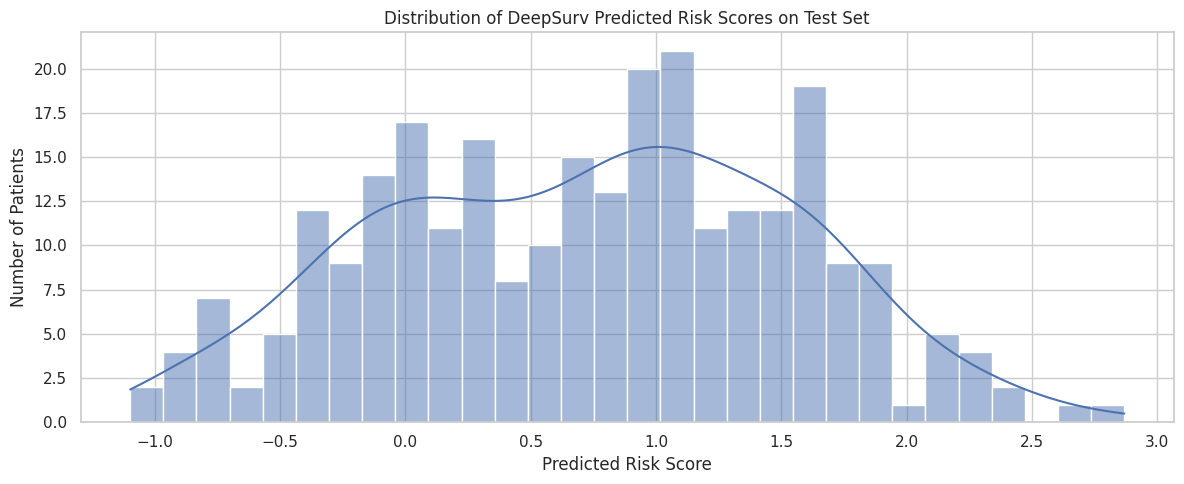

'/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/exp_1/hcc_exp1_deepsurv_risk_histogram.png'

In [ ]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 5))
sns.histplot(evaluation_df["risk_score"], bins=30, kde=True)
plt.title("Distribution of DeepSurv Predicted Risk Scores on Test Set")
plt.xlabel("Predicted Risk Score")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.savefig(RISK_HIST_PATH, dpi=300, bbox_inches="tight")
plt.show()

RISK_HIST_PATH

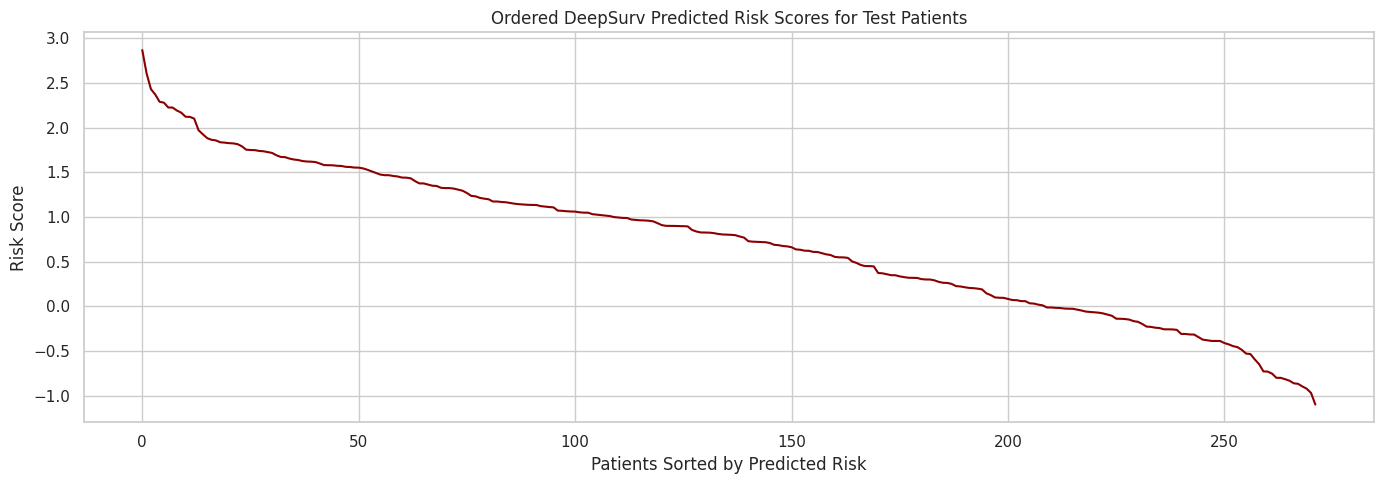

'/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/exp_1/hcc_exp1_deepsurv_ordered_risk_scores.png'

In [ ]:
evaluation_df_sorted = evaluation_df.sort_values("risk_score", ascending=False).reset_index(drop=True)

plt.figure(figsize=(14, 5))
plt.plot(evaluation_df_sorted["risk_score"].values, color="darkred")
plt.title("Ordered DeepSurv Predicted Risk Scores for Test Patients")
plt.xlabel("Patients Sorted by Predicted Risk")
plt.ylabel("Risk Score")
plt.tight_layout()
plt.savefig(ORDERED_RISK_PATH, dpi=300, bbox_inches="tight")
plt.show()

ORDERED_RISK_PATH

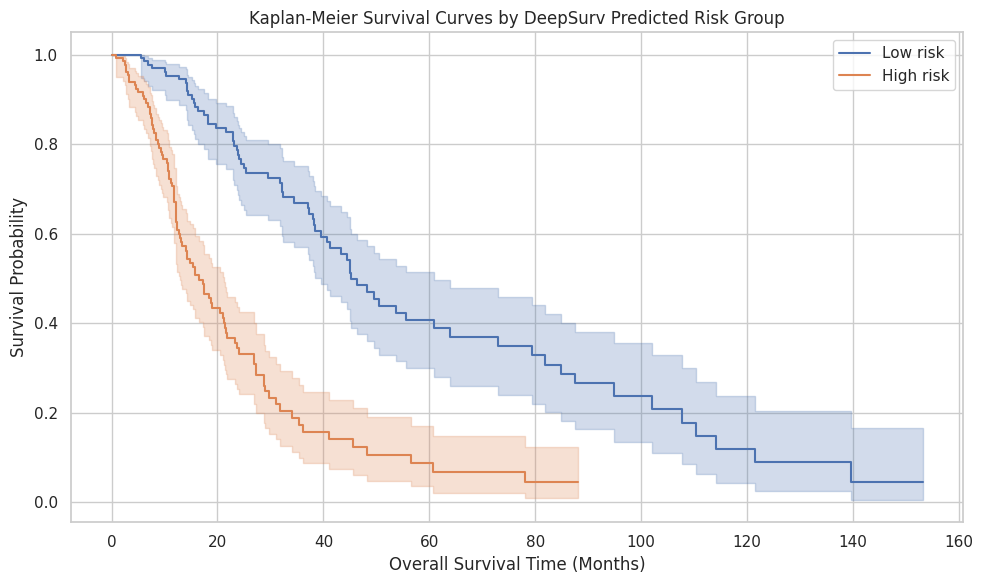

'/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/exp_1/hcc_exp1_deepsurv_km_risk_groups.png'

In [ ]:
kmf = KaplanMeierFitter()

plt.figure(figsize=(10, 6))

for group_name in ["Low risk", "High risk"]:
    group_df = evaluation_df[evaluation_df["risk_group"] == group_name]

    kmf.fit(
        durations=group_df[DURATION_COL],
        event_observed=group_df[EVENT_COL],
        label=group_name
    )
    kmf.plot_survival_function(ci_show=True)

plt.title("Kaplan-Meier Survival Curves by DeepSurv Predicted Risk Group")
plt.xlabel("Overall Survival Time (Months)")
plt.ylabel("Survival Probability")
plt.grid(True)
plt.tight_layout()
plt.savefig(KM_PLOT_PATH, dpi=300, bbox_inches="tight")
plt.show()

KM_PLOT_PATH

In [ ]:
low_risk_df = evaluation_df[evaluation_df["risk_group"] == "Low risk"]
high_risk_df = evaluation_df[evaluation_df["risk_group"] == "High risk"]

logrank_result = logrank_test(
    low_risk_df[DURATION_COL],
    high_risk_df[DURATION_COL],
    event_observed_A=low_risk_df[EVENT_COL],
    event_observed_B=high_risk_df[EVENT_COL]
)

print("Log-rank test p-value:", logrank_result.p_value)

Log-rank test p-value: 1.9310474184729047e-15


In [ ]:
selected_times = [12, 24, 36, 60]

for month in selected_times:
    closest_index = np.argmin(np.abs(event_times - month))
    evaluation_df[f"survival_prob_{month}m"] = survival_curves[:, closest_index]

evaluation_df.head()

,OS_MONTHS,OS_EVENT,risk_score,risk_group,survival_prob_12m,survival_prob_24m,survival_prob_36m,survival_prob_60m
0,28.980,1,0.897966,High risk,0.794782,0.543679,0.348900,0.139977
1,5.952,1,2.122432,High risk,0.457730,0.125760,0.027804,0.001243
2,9.984,0,0.549038,Low risk,0.850415,0.650577,0.475774,0.249799
3,23.652,1,2.226081,High risk,0.420286,0.100277,0.018801,0.000599
4,36.696,0,-0.057270,Low risk,0.915426,0.791007,0.666910,0.469320


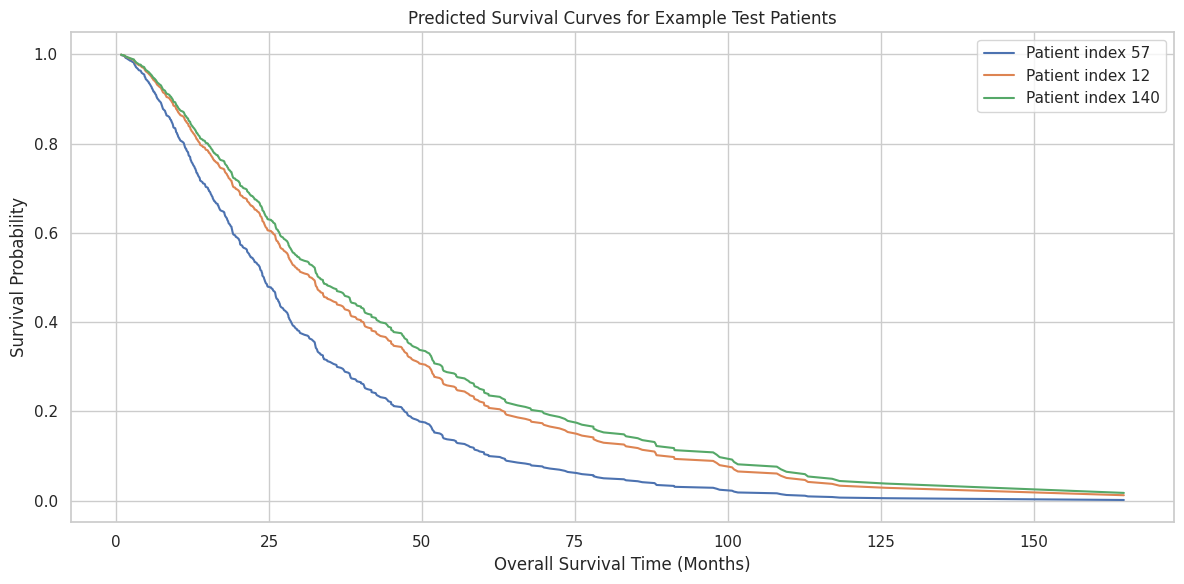

'/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/exp_1/hcc_exp1_deepsurv_example_survival_curves.png'

In [ ]:
import random

random.seed(42)
example_patients = random.sample(range(len(test_data)), 3)

plt.figure(figsize=(12, 6))

for patient_index in example_patients:
    plt.plot(
        event_times,
        survival_curves[patient_index],
        label=f"Patient index {patient_index}"
    )

plt.title("Predicted Survival Curves for Example Test Patients")
plt.xlabel("Overall Survival Time (Months)")
plt.ylabel("Survival Probability")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(SURVIVAL_CURVE_PLOT_PATH, dpi=300, bbox_inches="tight")
plt.show()

SURVIVAL_CURVE_PLOT_PATH

In [ ]:
evaluation_df.to_csv(PREDICTION_OUTPUT_PATH, index=False)

print("Saved predictions to:", PREDICTION_OUTPUT_PATH)

Saved predictions to: /content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/exp_1/hcc_exp1_deepsurv_test_predictions.csv


In [ ]:
metrics_rows = [
    {"metric": "C-index", "value": test_c_index},
    {"metric": "IBS", "value": ibs}
]

for t, auc in zip(time_points, auc_scores):
    metrics_rows.append({
        "metric": f"AUC_{int(t/12)}_year",
        "value": auc
    })

metrics_rows.append({"metric": "Mean_time_dependent_AUC", "value": mean_auc})
metrics_rows.append({"metric": "Log-rank_p_value", "value": logrank_result.p_value})

metrics_df = pd.DataFrame(metrics_rows)
metrics_df.to_csv(METRICS_PATH, index=False)

metrics_df

,metric,value
0,C-index,7.388639e-01
1,IBS,1.310131e-01
2,AUC_1_year,8.137278e-01
3,AUC_3_year,8.382949e-01
4,AUC_5_year,7.848972e-01
5,Mean_time_dependent_AUC,8.193663e-01
6,Log-rank_p_value,1.931047e-15


In [ ]:
PREDICTION_OUTPUT_PATH, METRICS_PATH

('/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/exp_1/hcc_exp1_deepsurv_test_predictions.csv',
 '/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/exp_1/hcc_exp1_deepsurv_metrics.csv')

The `Exp_1` DeepSurv evaluation notebook completed the final held-out test assessment of the saved best neural survival model. This notebook used the retrained `Exp_1` DeepSurv model on the untouched test set and evaluated it across discrimination, survival-probability accuracy, and risk-group separation. Since hyperparameter tuning and retraining were already finished earlier, this notebook represents the true final external performance check for the `Exp_1` DeepSurv pipeline.

The final test-set results were:
- C-index: `0.7389`
- IBS: `0.1310`
- AUC at 1 years: 0.8137
- AUC at 3 years: 0.8383
- AUC at 5 years: 0.7849
- Mean time-dependent AUC: 0.8194
- Log-rank p-value: `1.9310474184729047e-15`

These results show that the tuned DeepSurv model generalized well to unseen patients. The test C-index of `0.7364` indicates good overall survival-risk ranking ability, meaning the model can reliably order patients by relative prognosis. This is also very consistent with the earlier training-stage behavior, which supports the stability of the full tuning and retraining pipeline.

The IBS of `0.1299` is a good result and indicates that the predicted survival curves are reasonably accurate over time, not just useful for ranking. That matters because it means the model is contributing meaningful time-to-event prediction rather than only a relative risk score.

The time-dependent AUC profile is particularly strong:
- `0.8137` at 1 year
- `0.8383` at 3 years
- `0.7849` at 5 years

This suggests the model performs especially well for short- to medium-term survival discrimination, with its best separation around 3 years. The 5-year AUC is slightly lower, but still solid, which is a normal pattern in survival modeling because longer-horizon prediction is usually more difficult.

The mean time-dependent AUC of `0.8197` supports the same conclusion: overall discrimination across the major clinical time points is strong. The log-rank p-value of `4.07e-16` is extremely small, confirming that the model’s predicted high-risk and low-risk groups separate very clearly in Kaplan-Meier analysis. That is an important practical strength, because it shows the DeepSurv predictions translate into distinctly different survival strata rather than only abstract numeric scores.

Overall, this notebook confirms that the final `Exp_1` DeepSurv pipeline was successful end to end. The tuned model generalized well on the held-out test set, achieved strong ranking and time-dependent discrimination, maintained acceptable survival-probability accuracy, and produced highly significant Kaplan-Meier risk-group separation. The key conclusion is that `Exp_1` supports a robust DeepSurv model with strong prognostic performance and clinically meaningful patient stratification.This is not a case where one metric looks good and the others collapse. Instead:
- ranking performance is good (`C-index`)
- time-specific discrimination is strong (`AUCs`)
- overall survival prediction error is acceptable (`IBS`)
- risk-group separation is highly significant (`log-rank`)

**Observation**

The `Exp_1` DeepSurv evaluation shows a strong and internally consistent final test performance. The model achieved a test C-index of `0.7389`, which indicates good overall ranking of patients by survival risk on unseen data. The Integrated Brier Score of `0.1310` suggests that the predicted survival probabilities are reasonably accurate over time and not only useful for relative ordering.

The time-dependent AUC values show a very balanced pattern:
- `0.8137` at 1 year
- `0.8383` at 3 years
- `0.7849` at 5 years

This means the model is strongest at intermediate follow-up and remains solid even at 5 years, where survival prediction is generally harder. Another important observation is that the model separates high-risk and low-risk groups extremely clearly, as reflected by the very small log-rank p-value of `4.07e-16`. That gives the model not just statistical strength but also practical interpretability in terms of patient stratification.

A further reassuring point is the stability across the full workflow. The final test performance remains close to the cross-validated tuning performance and the retraining-stage behavior, which suggests the DeepSurv pipeline is stable and not obviously overfit.

**Conclusion**

The final conclusion from the `Exp_1` DeepSurv evaluation is that this pipeline successfully produced a robust prognostic survival model. It generalizes well to the held-out test set, provides strong discrimination across 1-, 3-, and 5-year horizons, maintains acceptable survival-probability accuracy, and yields highly significant Kaplan-Meier separation between predicted risk groups.

In short, `Exp_1` DeepSurv can be considered a successful end-to-end survival modeling pipeline and a credible model for final comparison against the CoxPH counterpart.